In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error

In [3]:
np.random.seed(0)
X = np.random.randn(200,6)
y = 5*X[:,0] + 3*X[:,1] - 2*X[:,2] + np.random.randn(200)    # X4,X5,X6 are noise
cols = [f"X{i+1}" for i in range(6)]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
sc = StandardScaler(); X_train = sc.fit_transform(X_train); X_test = sc.transform(X_test)

Linear: R2=0.9695  RMSE=1.1573
Ridge: R2=0.9687  RMSE=1.1727
Lasso: R2=0.9675  RMSE=1.1945
    Linear  Ridge  Lasso
X1   4.620  4.591  4.529
X2   3.082  3.064  2.990
X3  -1.877 -1.867 -1.801
X4   0.121  0.121  0.013
X5   0.105  0.106  0.000
X6  -0.057 -0.058 -0.000


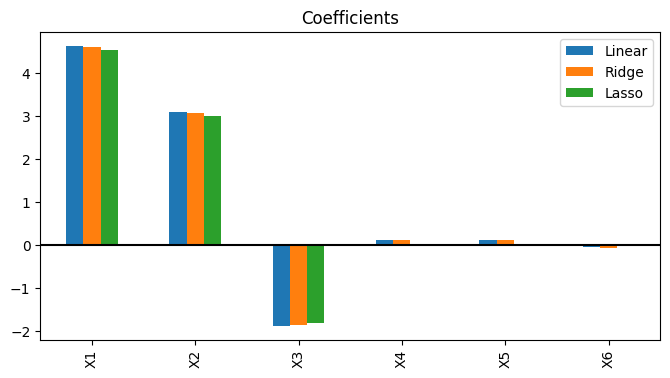

In [4]:
models = {"Linear":LinearRegression(), "Ridge":Ridge(alpha=1.0), "Lasso":Lasso(alpha=0.1)}
coef = pd.DataFrame(index=cols)
for name,m in models.items():
    m.fit(X_train,y_train); p = m.predict(X_test); coef[name] = m.coef_
    print(f"{name}: R2={r2_score(y_test,p):.4f}  RMSE={np.sqrt(mean_squared_error(y_test,p)):.4f}")
print(coef.round(3))
coef.plot(kind="bar",figsize=(8,4)); plt.axhline(0,color="k"); plt.title("Coefficients"); plt.show()

In [5]:
for a in [0.01,0.1,1,2]:                                    # effect of alpha on Lasso
    print("Lasso alpha",a,"-> non-zero coefficients:",(Lasso(alpha=a).fit(X_train,y_train).coef_!=0).sum())

Lasso alpha 0.01 -> non-zero coefficients: 6
Lasso alpha 0.1 -> non-zero coefficients: 4
Lasso alpha 1 -> non-zero coefficients: 3
Lasso alpha 2 -> non-zero coefficients: 3
